<a href="https://colab.research.google.com/github/shrutz12f-dotcom/weather-Forecasting/blob/main/weatherforecasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

# CELL 1: Import libraries and upload the ZIP file

import os
import zipfile
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

uploaded = files.upload()

zip_path = next(
    name for name in uploaded.keys()
    if name.lower().endswith(".zip")
)

extract_path = "/content/climate_dataset"
os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("ZIP file extracted successfully!")

# Find all CSV files inside the extracted folder
csv_files = glob.glob(
    os.path.join(extract_path, "**", "*.csv"),
    recursive=True
)

print("\nCSV files found:")
for file in csv_files:
    print(file)


Saving archive.zip to archive (1).zip
ZIP file extracted successfully!

CSV files found:
/content/climate_dataset/DailyDelhiClimateTrain.csv
/content/climate_dataset/DailyDelhiClimateTest.csv


In [2]:

if not csv_files:
    raise ValueError("ZIP file-la CSV file kidaikkala!")

csv_path = max(csv_files, key=os.path.getsize)

df = pd.read_csv(csv_path)

print("Selected file:", csv_path)
print("Original dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())


Selected file: /content/climate_dataset/DailyDelhiClimateTrain.csv
Original dataset shape: (1462, 5)

Column names:
['date', 'meantemp', 'humidity', 'wind_speed', 'meanpressure']

First 5 rows:


,date,meantemp,humidity,wind_speed,meanpressure
0,2013-01-01,10.000000,84.500000,0.000000,1015.666667
1,2013-01-02,7.400000,92.000000,2.980000,1017.800000
2,2013-01-03,7.166667,87.000000,4.633333,1018.666667
3,2013-01-04,8.666667,71.333333,1.233333,1017.166667
4,2013-01-05,6.000000,86.833333,3.700000,1016.500000


In [3]:

# Find date column
date_candidates = [
    c for c in df.columns
    if c.strip().lower() in [
        "date", "datetime", "timestamp"
    ]
]

if not date_candidates:
    raise ValueError("Date column identify panna mudiyala!")

date_col = date_candidates[0]

df[date_col] = pd.to_datetime(
    df[date_col], errors="coerce"
)

df = df.dropna(subset=[date_col])
df = df.sort_values(date_col)
df = df.drop_duplicates(subset=[date_col])

# Convert weather columns to numeric
for c in df.columns:
    if c != date_col:
        df[c] = pd.to_numeric(df[c], errors="coerce")

# Find temperature column
temp_names = [
    "meantemp", "mean_temp", "mean_temperature",
    "temperature", "temp", "avg_temp",
    "average_temperature"
]

temp_col = next(
    (
        c for c in df.columns
        if c.strip().lower() in temp_names
    ),
    None
)

if temp_col is None:
    raise ValueError(
        "Temperature column kidaikkala. "
        "Cell 2 output check pannu."
    )

# Daily frequency
df = df.set_index(date_col).sort_index()
df = df.asfreq("D")

numeric_cols = df.select_dtypes(
    include=np.number
).columns

df[numeric_cols] = df[numeric_cols].interpolate(
    method="time",
    limit_direction="both"
)

df = df.reset_index()
df = df.dropna(subset=[temp_col])

print("Date column:", date_col)
print("Temperature column:", temp_col)
print("Cleaned records:", len(df))

display(df.head())


Date column: date
Temperature column: meantemp
Cleaned records: 1462


,date,meantemp,humidity,wind_speed,meanpressure
0,2013-01-01,10.000000,84.500000,0.000000,1015.666667
1,2013-01-02,7.400000,92.000000,2.980000,1017.800000
2,2013-01-03,7.166667,87.000000,4.633333,1018.666667
3,2013-01-04,8.666667,71.333333,1.233333,1017.166667
4,2013-01-05,6.000000,86.833333,3.700000,1016.500000


In [4]:

df = df.sort_values(date_col).reset_index(drop=True)

if len(df) < 1000:
    raise ValueError(
        "1,000 daily records available illa!"
    )

# Select 1,000 consecutive daily records
df = df.iloc[:1000].copy()

# Select numeric weather features
feature_cols = [
    c for c in df.select_dtypes(
        include=np.number
    ).columns
    if df[c].nunique() > 1
]

print("Selected records:", len(df))
print("Date range:", df[date_col].min(),
      "to", df[date_col].max())

print("Features:", feature_cols)
print("Target:", temp_col)


Selected records: 1000
Date range: 2013-01-01 00:00:00 to 2015-09-27 00:00:00
Features: ['meantemp', 'humidity', 'wind_speed', 'meanpressure']
Target: meantemp


In [5]:

from sklearn.preprocessing import MinMaxScaler

LOOKBACK = 30
split_idx = 800

train_df = df.iloc[:split_idx]
test_df = df.iloc[split_idx:]

# Fit scaler using training data only
feature_scaler = MinMaxScaler()

feature_scaler.fit(
    train_df[feature_cols]
)

X_scaled = feature_scaler.transform(
    df[feature_cols]
)

# Separate temperature scaler
target_scaler = MinMaxScaler()

target_scaler.fit(
    train_df[[temp_col]]
)

y_scaled = target_scaler.transform(
    df[[temp_col]]
).ravel()

print("Training records:", len(train_df))
print("Testing records:", len(test_df))
print("Lookback days:", LOOKBACK)
print("Feature count:", len(feature_cols))


Training records: 800
Testing records: 200
Lookback days: 30
Feature count: 4


In [6]:

X = []
y = []
target_indices = []

for i in range(LOOKBACK, len(df)):
    X.append(
        X_scaled[i-LOOKBACK:i]
    )

    y.append(y_scaled[i])
    target_indices.append(i)

X = np.array(X)
y = np.array(y)
target_indices = np.array(target_indices)

train_mask = target_indices < split_idx
test_mask = target_indices >= split_idx

X_train = X[train_mask]
y_train = y[train_mask]

X_test = X[test_mask]
y_test = y[test_mask]

test_indices = target_indices[test_mask]

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)


X_train shape: (770, 30, 4)
y_train shape: (770,)
X_test shape: (200, 30, 4)
y_test shape: (200,)


In [7]:

import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(42)

model = Sequential([
    tf.keras.Input(
        shape=(LOOKBACK, len(feature_cols))
    ),

    LSTM(64, return_sequences=True),
    Dropout(0.2),

    LSTM(32),

    Dense(16, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 64)         │        17,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,625 (119.63 KB)

 Trainable params: 30,625 (119.63 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.15,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

print("Training completed!")


Epoch 1/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 4s 48ms/step - loss: 0.1686 - mae: 0.3236 - val_loss: 0.1230 - val_mae: 0.3378
Epoch 2/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - loss: 0.0193 - mae: 0.1097 - val_loss: 0.0126 - val_mae: 0.0904
Epoch 3/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - loss: 0.0143 - mae: 0.0982 - val_loss: 0.0095 - val_mae: 0.0771
Epoch 4/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - loss: 0.0079 - mae: 0.0732 - val_loss: 0.0085 - val_mae: 0.0733
Epoch 5/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 0.0068 - mae: 0.0672 - val_loss: 0.0085 - val_mae: 0.0733
Epoch 6/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - loss: 0.0053 - mae: 0.0584 - val_loss: 0.0089 - val_mae: 0.0747
Epoch 7/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - loss: 0.0053 - mae: 0.0586 - val_loss: 0.0087 - val_mae: 0.0741
Epoch 8/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 0.0050 - mae: 0.0568 - val_loss: 0.0088 - val_mae: 0.0750
Epoch 9/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - loss: 0.004

In [9]:

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

pred_scaled = model.predict(
    X_test, verbose=0
)

# Convert normalized values back to temperature
y_pred = target_scaler.inverse_transform(
    pred_scaled
).ravel()

y_actual = target_scaler.inverse_transform(
    y_test.reshape(-1, 1)
).ravel()

mae = mean_absolute_error(
    y_actual, y_pred
)

rmse = np.sqrt(
    mean_squared_error(y_actual, y_pred)
)

print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))

results = pd.DataFrame({
    "Date": df.iloc[test_indices][date_col].values,
    "Actual Temperature": y_actual,
    "Predicted Temperature": y_pred
})

display(results.head(10))


MAE: 1.9607
RMSE: 2.4957


,Date,Actual Temperature,Predicted Temperature
0,2015-03-12,20.500000,19.293474
1,2015-03-13,21.375000,19.250156
2,2015-03-14,21.500000,19.306805
3,2015-03-15,17.625000,19.432526
4,2015-03-16,19.857143,19.338217
5,2015-03-17,20.875000,19.288675
6,2015-03-18,20.250000,19.403187
7,2015-03-19,21.125000,19.595854
8,2015-03-20,22.500000,19.831268
9,2015-03-21,24.875000,20.136770


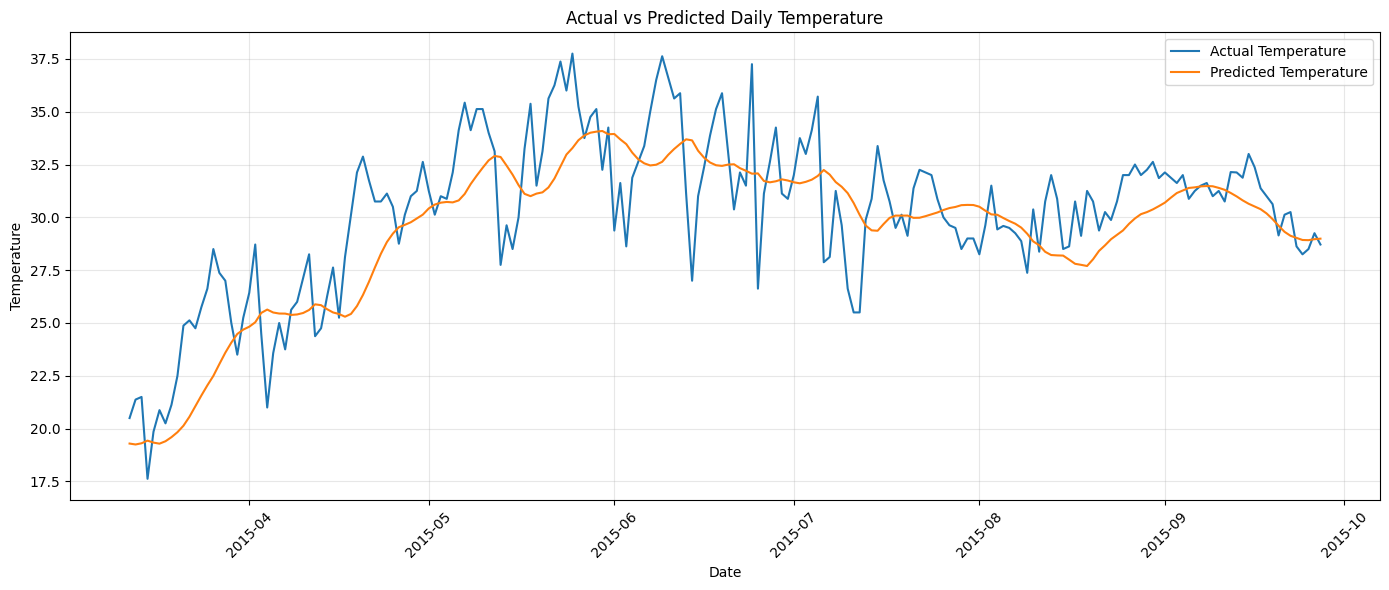

In [10]:

plt.figure(figsize=(14, 6))

plt.plot(
    results["Date"],
    results["Actual Temperature"],
    label="Actual Temperature"
)

plt.plot(
    results["Date"],
    results["Predicted Temperature"],
    label="Predicted Temperature"
)

plt.title("Actual vs Predicted Daily Temperature")
plt.xlabel("Date")
plt.ylabel("Temperature")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [11]:

FORECAST_DAYS = 7

future_window = X_scaled[-LOOKBACK:].copy()

last_features = df[feature_cols].iloc[-1].copy()
last_date = pd.Timestamp(df[date_col].iloc[-1])

forecasts = []

for step in range(FORECAST_DAYS):

    next_scaled = model.predict(
        future_window[np.newaxis, :, :],
        verbose=0
    )[0, 0]

    next_temp = target_scaler.inverse_transform(
        np.array([[next_scaled]])
    )[0, 0]

    next_date = last_date + pd.Timedelta(
        days=step + 1
    )

    forecasts.append({
        "Date": next_date,
        "Forecast Temperature": next_temp
    })

    # Use predicted temperature for next step
    next_features = last_features.copy()
    next_features[temp_col] = next_temp

    next_row = feature_scaler.transform(
        next_features[feature_cols].to_frame().T
    )[0]

    future_window = np.vstack([
        future_window[1:],
        next_row
    ])

future_df = pd.DataFrame(forecasts)

display(future_df.round(3))


,Date,Forecast Temperature
0,2015-09-28,28.913000
1,2015-09-29,28.796000
2,2015-09-30,28.643000
3,2015-10-01,28.459999
4,2015-10-02,28.257999
5,2015-10-03,28.044001
6,2015-10-04,27.823999


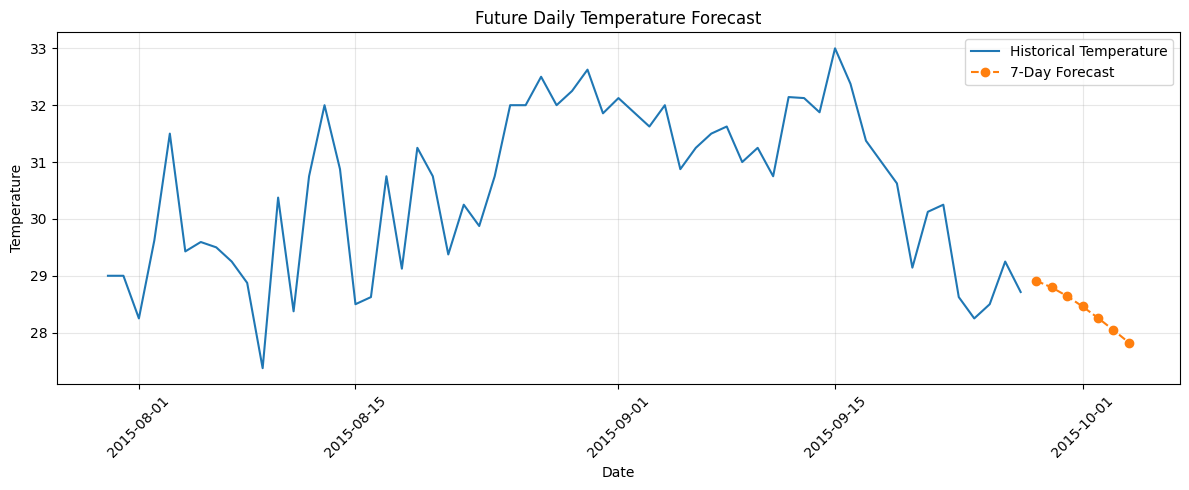

In [12]:

plt.figure(figsize=(12, 5))

plt.plot(
    df[date_col].tail(60),
    df[temp_col].tail(60),
    label="Historical Temperature"
)

plt.plot(
    future_df["Date"],
    future_df["Forecast Temperature"],
    marker="o",
    linestyle="--",
    label="7-Day Forecast"
)

plt.title("Future Daily Temperature Forecast")
plt.xlabel("Date")
plt.ylabel("Temperature")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [13]:

results.to_csv(
    "/content/test_results.csv",
    index=False
)

future_df.to_csv(
    "/content/future_forecast.csv",
    index=False
)

model.save("/content/temperature_lstm.keras")

print("All output files saved!")

files.download("/content/test_results.csv")
files.download("/content/future_forecast.csv")
files.download("/content/temperature_lstm.keras")


All output files saved!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>